## Main Detection Code

- Step 1: Load and understand the dataset
- Step 2: Display a sample image
- Step 3: Check image dimensions
- Step 4: Load all images
- Step 5: Split data into training and testing sets

> Imported Libraries
---

In [2]:
import os
from keras.preprocessing import image
import pandas as pd

> Loading Dataset
---

In [8]:
dataset = pd.read_csv("../dataset/train/_classes.csv")
df = dataset
print(df.head())
print(df.columns)
print(df["0"].value_counts() if "0" in df.columns else df.iloc[:, -1].value_counts())

                                            filename   with_mask  \
0  26-with-mask_jpg.rf.fb2a4fd14461ba4e7d981f51d9...           1   
1     66_jpg.rf.fb48333563aba0cd06afba343f625d98.jpg           0   
2  153-with-mask_jpg.rf.fb584ce29ce6d9a3123a04d80...           1   
3  29-with-mask_jpg.rf.fb9ecac8d3dc335a43b79a9438...           1   
4  augmented_image_315_jpg.rf.fba9c25c6675c5a039f...           1   

    without_mask  
0              0  
1              1  
2              0  
3              0  
4              0  
Index(['filename', ' with_mask', ' without_mask'], dtype='str')
 without_mask
0    644
1    635
Name: count, dtype: int64


> Data Cleaning
---

In [11]:
df.columns = df.columns.str.strip()

print(df[["with_mask", "without_mask"]].sum())

with_mask       644
without_mask    635
dtype: int64


> Image inspection
---

..\dataset\train\26-with-mask_jpg.rf.fb2a4fd14461ba4e7d981f51d994136b.jpg


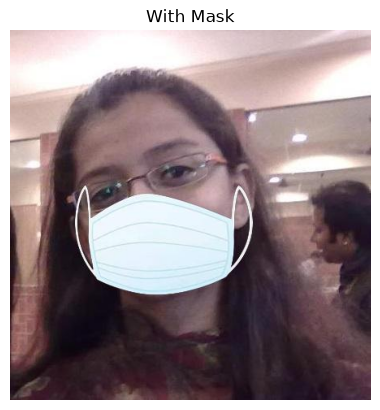

In [20]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

img_path = Path("../dataset/train") / df["filename"].iloc[0]
print(img_path)

img = cv2.imread(str(img_path))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.title("With Mask" if df["with_mask"].iloc[0] == 1 else "Without Mask")
plt.axis("off");


# img = cv2.imrea

> Image Resizing & Normalizing Pixel Values
---

- **Normalized:** dividing by 255 means, (0,255) to (0,1)
- **dtype=np.float32:** When representing discrete classes

In [19]:
print(img.shape)

(455, 444, 3)


In [50]:
import numpy as np

X = []
y = []

img_dir = Path("../dataset/train")

for _, row in df.iterrows():
    img_path = img_dir / row["filename"]
    img = cv2.imread(str(img_path))

    if img is None:
        continue

    img = cv2.resize(img, (224,224))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    X.append(img)
    y.append(row["with_mask"])

X = np.array(X, dtype=np.float32) / 255.0
y = np.array(y, dtype=np.int32)

print("Images:", X.shape)
print("Labels:", y.shape)

Images: (1279, 224, 224, 3)
Labels: (1279,)
